In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import datetime as dt  

df = pd.read_excel("task1_marketplace_delivery_sla_raw.xlsx")      # read excel into a table
print(df.shape)
df.head(15)

(10, 13)


,order_id,customer_id,order_date,shipped_at,delivered_at,updated_at,city,courier,payment_status,order_status,promised_days,order_value,is_test_order
0,O1001,C01,29-04-26,2026-01-05 00:00:00,2026-03-05 00:00:00,2026-03-05 00:00:00,Bengaluru,ShipQuick,Paid,Delivered,2,1200,No
1,O1002,C02,2026-02-05 00:00:00,2026-03-05 00:00:00,2026-07-05 00:00:00,2026-07-05 00:00:00,Mumbai,shipquick,pending,delivered,3,900,No
2,O1002,C02,2026-02-05 00:00:00,2026-03-05 00:00:00,2026-07-05 00:00:00,2026-08-05 00:00:00,Mumbai,ShipQuick,Paid,Delivered,3,900,No
3,O1003,C03,2026-04-05 00:00:00,2026-05-05 00:00:00,2026-06-05 00:00:00,2026-06-05 00:00:00,Delhi,FastBee,Pending,Delivered,2,650,No
4,O1004,C04,2026-05-05 00:00:00,2026-06-05 00:00:00,2026-01-06 00:00:00,2026-01-06 00:00:00,Pune,Blue Dart,Paid,Delivered,4,2000,No
5,O1005,C05,2026-08-05 00:00:00,2026-09-05 00:00:00,NaN,2026-10-05 00:00:00,Chennai,Fastbee,Paid,Cancelled,3,700,No
6,O1006,C06,2026-10-05 00:00:00,2026-11-05 00:00:00,14-05-26,14-05-26,Mumbai,Bluedart,Paid,Delivered,3,1500,No
7,O1006,C06,2026-10-05 00:00:00,2026-11-05 00:00:00,14-05-26,14-05-26,Mumbai,Bluedart,Paid,Delivered,3,1500,No
8,O1007,C07,2026-12-05 00:00:00,13-05-26,15-05-26,15-05-26,Bangalore,ShipQuick,Paid,Delivered,2,1,Yes
9,O1008,C08,15-05-26,16-05-26,18-05-26,18-05-26,Pune,FastBee,Paid,Delivered,-2,500,No


In [16]:
df.info()   # column types + missing values
# spot spelling variants / odd values
for c in ["courier", "order_status", "payment_status", "is_test_order", "promised_days"]:
    print(df[c].value_counts(dropna=False), "\n")
print(df["order_id"].duplicated().sum())   # duplicate orders

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   order_id        10 non-null     object
 1   customer_id     10 non-null     object
 2   order_date      10 non-null     object
 3   shipped_at      10 non-null     object
 4   delivered_at    9 non-null      object
 5   updated_at      10 non-null     object
 6   city            10 non-null     object
 7   courier         10 non-null     object
 8   payment_status  10 non-null     object
 9   order_status    10 non-null     object
 10  promised_days   10 non-null     int64 
 11  order_value     10 non-null     int64 
 12  is_test_order   10 non-null     object
dtypes: int64(2), object(11)
memory usage: 1.1+ KB
courier
ShipQuick    3
FastBee      2
Bluedart     2
shipquick    1
Blue Dart    1
Fastbee      1
Name: count, dtype: int64 

order_status
Delivered    8
delivered    1
Cancelled    1
Nam

In [17]:
def parse_date(v):
    if pd.isna(v):
        return pd.NaT                                           # empty -> missing date
    if isinstance(v, (dt.datetime, pd.Timestamp)):              # real Excel date: day/month swapped
        return pd.Timestamp(year=v.year, month=v.day, day=v.month)
    return pd.to_datetime(str(v), format="%d-%m-%y")            # text date (day-month-year)

for c in ["order_date", "shipped_at", "delivered_at", "updated_at"]:
    df[c] = df[c].apply(parse_date)

df[["order_id", "shipped_at", "delivered_at"]]  # check: shipped <= delivered

,order_id,shipped_at,delivered_at
0,O1001,2026-05-01,2026-05-03
1,O1002,2026-05-03,2026-05-07
2,O1002,2026-05-03,2026-05-07
3,O1003,2026-05-05,2026-05-06
4,O1004,2026-05-06,2026-06-01
5,O1005,2026-05-09,NaT
6,O1006,2026-05-11,2026-05-14
7,O1006,2026-05-11,2026-05-14
8,O1007,2026-05-13,2026-05-15
9,O1008,2026-05-16,2026-05-18


In [18]:
# unify courier spellings
df["courier"] = (df["courier"].str.strip().str.lower().str.replace(" ", "")
                 .map({"shipquick": "ShipQuick", "fastbee": "FastBee", "bluedart": "BlueDart"}))
# unify casing
for c in ["order_status", "payment_status", "is_test_order"]:
    df[c] = df[c].str.strip().str.title()

df["courier"].value_counts()  # should be 3 couriers

courier
ShipQuick    4
FastBee      3
BlueDart     3
Name: count, dtype: int64

In [20]:
# keep the latest update of each order
df = (df.sort_values(["order_id", "updated_at"])
        .drop_duplicates("order_id", keep="last")
        .reset_index(drop=True))
len(df)  # 10 -> 8

8

In [21]:
df["actual_transit_days"] = (df["delivered_at"] - df["shipped_at"]).dt.days  # days taken
df["delivery_status"] = (df["actual_transit_days"] <= df["promised_days"]).map({True: "On Time", False: "Late"})
df.loc[df["actual_transit_days"].isna(), "delivery_status"] = pd.NA  # not delivered -> no status

In [22]:
eligible = df[
    (df["is_test_order"] == "No") &            # no test orders
    (df["order_status"] == "Delivered") &      # no cancelled
    (df["promised_days"] > 0) &                # no invalid promise (-2)
    (df["actual_transit_days"] >= 0) &         # delivery not before shipping
    (df["delivered_at"] >= "2026-05-01") & (df["delivered_at"] < "2026-06-01")  # May only
]
eligible[["order_id", "courier", "actual_transit_days", "promised_days", "delivery_status"]]  # expect 4 rows

,order_id,courier,actual_transit_days,promised_days,delivery_status
0,O1001,ShipQuick,2.0,2,On Time
1,O1002,ShipQuick,4.0,3,Late
2,O1003,FastBee,1.0,2,On Time
5,O1006,BlueDart,3.0,3,On Time


In [23]:
summary = (eligible.groupby("courier")
           .agg(eligible_orders=("order_id", "count"),                                   # total orders
                on_time_orders=("delivery_status", lambda s: (s == "On Time").sum()))     # on-time orders
           .reset_index())
summary["on_time_rate"] = (summary["on_time_orders"] / summary["eligible_orders"]).round(2)  # ratio
summary

,courier,eligible_orders,on_time_orders,on_time_rate
0,BlueDart,1,1,1.0
1,FastBee,1,1,1.0
2,ShipQuick,2,1,0.5


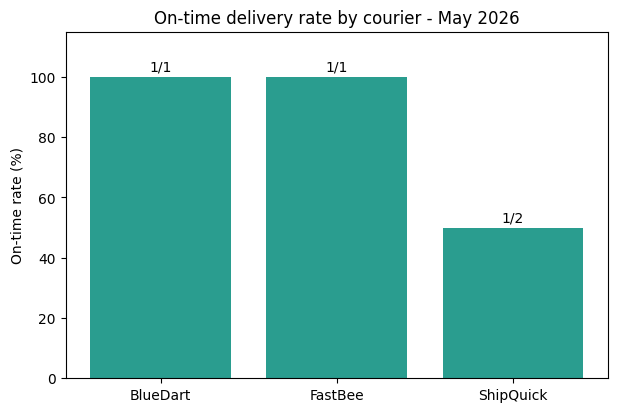

In [ ]:
plt.figure(figsize=(7, 4.5))
bars = plt.bar(summary["courier"], summary["on_time_rate"] * 100, color="#2a9d8f")
for b, n, t in zip(bars, summary["on_time_orders"], summary["eligible_orders"]):
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 2, f"{n}/{t}", ha="center")  # show sample size
plt.ylabel("On-time rate (%)")
plt.title("On-time delivery rate by courier - May 2026")
plt.ylim(0, 115)
plt.savefig("chart1_on_time_rate.png", dpi=150, bbox_inches="tight")
plt.show()

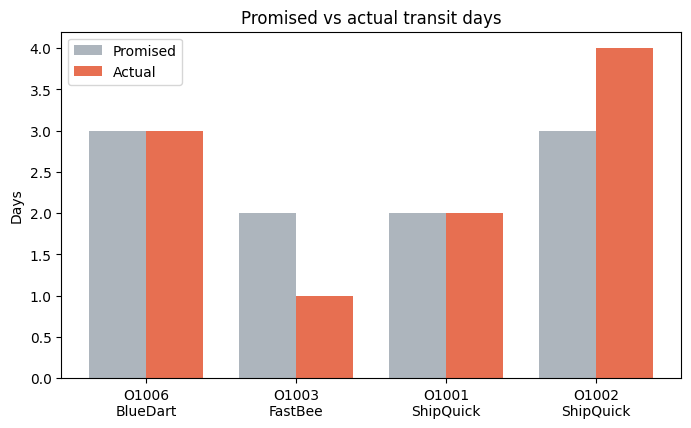

In [ ]:
e = eligible.sort_values("courier")
x = range(len(e)); w = 0.38                # bar positions and width
plt.figure(figsize=(8, 4.5))
plt.bar([i - w/2 for i in x], e["promised_days"], w, label="Promised", color="#adb5bd")       # grey = promised
plt.bar([i + w/2 for i in x], e["actual_transit_days"], w, label="Actual", color="#e76f51")   # red = actual
plt.xticks(list(x), e["order_id"] + "\n" + e["courier"])
plt.ylabel("Days"); plt.title("Promised vs actual transit days"); plt.legend()
plt.savefig("chart2_promised_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
summary.to_csv("courier_on_time_summary.csv", index=False)  # final result file